# Tugas Data Preprocessing — Studi Kasus Transaksi E-Commerce (NusantaraMart)

Notebook ini berisi alur lengkap **Data Preprocessing** yang siap dijalankan di **Google Colab**:
1. **Load Dataset & Audit Awal** (dimensi, tipe data, duplikat, *missing values*, dan statistik deskriptif)
2. **Data Cleaning**:
   - Penghapusan data duplikat (duplikat identik & duplikat `ID_Transaksi`)
   - Standardisasi teks kategorik (spasi berlebih, huruf kapital, singkatan, dan *typo*)
   - Standardisasi format tanggal (`Tanggal_Transaksi`)
   - Pembersihan nilai tidak valid / *noise* (angka negatif/nol dan nilai di luar rentang logis)
3. **Penanganan *Missing Values* Berbasis Statistik Deskriptif** (Mean, Median, Modus, dan Skewness)
4. **Deteksi & Penanganan *Outliers*** (Metode IQR & *Capping* / *Winsorization*)
5. **Reduksi Data, *Encoding*, dan *Feature Scaling*** (*Ordinal Encoding*, *One-Hot Encoding*, `StandardScaler`)
6. **Ekspor Dataset Bersih** ke format CSV

## 1. Import Library & Load Dataset di Google Colab

In [ ]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, MinMaxScaler

# Pengaturan tampilan tabel dan grafik
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)
sns.set_theme(style='whitegrid')

file_path = 'dataset_transaksi_ecommerce_kotor.csv'

# Jika dijalankan di Google Colab dan file belum diunggah ke folder kerja, munculkan tombol upload
if not os.path.exists(file_path):
    try:
        from google.colab import files
        print('Silakan unggah file dataset_transaksi_ecommerce_kotor.csv:')
        uploaded = files.upload()
        file_path = list(uploaded.keys())[0]
    except ImportError:
        raise FileNotFoundError(f'File {file_path} tidak ditemukan di direktori kerja.')

df_raw = pd.read_csv(file_path)
print(f'Dataset berhasil dimuat! Ukuran awal: {df_raw.shape[0]} baris x {df_raw.shape[1]} kolom')
df_raw.head(10)

Silakan unggah file dataset_transaksi_ecommerce_kotor.csv:


Saving dataset_transaksi_ecommerce_kotor_colab.csv to dataset_transaksi_ecommerce_kotor_colab.csv
Dataset berhasil dimuat! Ukuran awal: 120 baris x 11 kolom


,ID_Transaksi,Tanggal_Transaksi,Usia_Pelanggan,Jenis_Kelamin,Kota_Domisili,Kategori_Member,Kategori_Produk,Jumlah_Beli,Total_Belanja_IDR,Rating_Kepuasan,Metode_Pembayaran
0,TRX-1045,2026-05-02,NaN,Perempuan,Bandung,Gold,Makanan & Minuman,4.0,509000.0,4.3,COD
1,TRX-1048,2026-05-10,38.0,Laki-laki,Malang,Gold,Rumah Tangga,NaN,357000.0,4.9,Transfer Bank
2,TRX-1005,15/01/2026,29.0,NaN,Malang,Gold,Kesehatan & Kecantikan,3.0,302000.0,4.3,E-Wallet
3,TRX-1056,2026.05.31,38.0,Perempuan,NaN,Bronze,Fashion,6.0,1231000.0,3.9,E-Wallet
4,TRX-1027,15/03/2026,23.0,Perempuan,Sidoarjo,Bronze,elektronik,3.0,297000.0,5.0,E-Wallet
5,TRX-1065,24-Jun-2026,37.0,Perempuan,MALANG,Gold,Makanan & Minuman,4.0,2658000.0,3.7,COD
6,TRX-1074,2026.07.18,42.0,Perempuan,Surabaya,Gold,Rumah Tangga,3.0,534000.0,3.2,Kartu Kredit
7,TRX-1011,2026-01-31,148.0,Laki-laki,Jakarta,Gold,Elektronik,2.0,137000.0,5.0,Transfer Bank
8,TRX-1041,2026.04.21,36.0,Perempuan,gresik,Silver,Fashion,4.0,991000.0,4.5,Kartu Kredit
9,TRX-1108,2026-10-16,32.0,Perempuan,Surabaya,NaN,Makanan & Minuman,8.0,1692000.0,4.4,Transfer Bank


## 2. Audit Kualitas Data & Statistik Deskriptif Awal

In [ ]:
print("\n=== INFORMASI TIPE DATA ===")
df_raw.info()

print("\n=== CEK DATA DUPLIKAT ===")
print("Jumlah baris duplikat identik :", df_raw.duplicated().sum())
print("Jumlah duplikat ID_Transaksi  :", df_raw.duplicated(subset=['ID_Transaksi']).sum())

print("\n=== JUMLAH & PERSENTASE MISSING VALUES ===")
missing_df = pd.DataFrame({
    'Missing_Count': df_raw.isnull().sum(),
    'Missing_Percent (%)': (df_raw.isnull().sum() / len(df_raw) * 100).round(2)
})
display(missing_df[missing_df['Missing_Count'] > 0])

print("\n=== STATISTIK DESKRIPTIF VARIABEL NUMERIK (MENTAH) ===")
display(df_raw.describe().T)

print("\n=== STATISTIK DESKRIPTIF VARIABEL KATEGORIK (MENTAH) ===")
display(df_raw.describe(include='object').T)

cat_cols = ['Jenis_Kelamin', 'Kota_Domisili', 'Kategori_Member', 'Kategori_Produk', 'Metode_Pembayaran']
for col in cat_cols:
    print(f"Nilai unik {col}: {df_raw[col].unique().tolist()}")


=== INFORMASI TIPE DATA ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 120 entries, 0 to 119
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   ID_Transaksi       120 non-null    object 
 1   Tanggal_Transaksi  120 non-null    object 
 2   Usia_Pelanggan     110 non-null    float64
 3   Jenis_Kelamin      115 non-null    object 
 4   Kota_Domisili      115 non-null    object 
 5   Kategori_Member    115 non-null    object 
 6   Kategori_Produk    116 non-null    object 
 7   Jumlah_Beli        113 non-null    float64
 8   Total_Belanja_IDR  111 non-null    float64
 9   Rating_Kepuasan    113 non-null    float64
 10  Metode_Pembayaran  115 non-null    object 
dtypes: float64(4), object(7)
memory usage: 10.4+ KB

=== CEK DATA DUPLIKAT ===
Jumlah baris duplikat identik : 6
Jumlah duplikat ID_Transaksi  : 7

=== JUMLAH & PERSENTASE MISSING VALUES ===


,Missing_Count,Missing_Percent (%)
Usia_Pelanggan,10,8.33
Jenis_Kelamin,5,4.17
Kota_Domisili,5,4.17
Kategori_Member,5,4.17
Kategori_Produk,4,3.33
Jumlah_Beli,7,5.83
Total_Belanja_IDR,9,7.50
Rating_Kepuasan,7,5.83
Metode_Pembayaran,5,4.17



=== STATISTIK DESKRIPTIF VARIABEL NUMERIK (MENTAH) ===


,count,mean,std,min,25%,50%,75%,max
Usia_Pelanggan,110.0,3.197273e+01,1.965410e+01,-24.0,27.0,30.0,34.0,175.0
Jumlah_Beli,113.0,1.403540e+01,7.908494e+01,-3.0,3.0,4.0,5.0,720.0
Total_Belanja_IDR,111.0,3.443189e+06,1.544180e+07,-185000.0,439500.0,686000.0,1438500.0,125000000.0
Rating_Kepuasan,113.0,4.297345e+00,1.099794e+00,-1.5,3.9,4.3,4.6,12.0



=== STATISTIK DESKRIPTIF VARIABEL KATEGORIK (MENTAH) ===


,count,unique,top,freq
ID_Transaksi,120,113,TRX-1066,2
Tanggal_Transaksi,120,113,2026.06.26,2
Jenis_Kelamin,115,9,Perempuan,65
Kota_Domisili,115,12,Surabaya,34
Kategori_Member,115,9,Bronze,32
Kategori_Produk,116,9,Fashion,32
Metode_Pembayaran,115,9,E-Wallet,40


Nilai unik Jenis_Kelamin: ['Perempuan', 'Laki-laki', nan, 'laki-laki', 'Pria', 'L', 'P', 'Wanita', 'perempuan', '  Perempuan ']
Nilai unik Kota_Domisili: ['Bandung', 'Malang', nan, 'Sidoarjo', 'MALANG', 'Surabaya', 'Jakarta', 'gresik', '  Surabaya  ', 'Gresik', 'SBY', 'surabaya', '  jakarta ']
Nilai unik Kategori_Member: ['Gold', 'Bronze', 'Silver', nan, 'GOLD', 'Platinum', 'platinum', '  Bronze ', 'Sliver', 'gold']
Nilai unik Kategori_Produk: ['Makanan & Minuman', 'Rumah Tangga', 'Kesehatan & Kecantikan', 'Fashion', 'elektronik', 'Elektronik', 'Makanan & minuman', nan, 'Elektronic', '  Fashion ']
Nilai unik Metode_Pembayaran: ['COD', 'Transfer Bank', 'E-Wallet', 'Kartu Kredit', nan, 'TF Bank', '  COD ', 'Ewallet', 'e-wallet', 'cod']


,Nama Variabel,Tipe Awal,Kategori Data,Missing,% Missing
0,ID_Transaksi,object,Kategorik (ID),0,0.00
1,Tanggal_Transaksi,object,Temporal,0,0.00
2,Usia_Pelanggan,float64,Numerik,10,8.33
3,Jenis_Kelamin,object,Kategorik Nominal,5,4.17
4,Kota_Domisili,object,Kategorik Nominal,5,4.17
5,Kategori_Member,object,Kategorik Ordinal,5,4.17
6,Kategori_Produk,object,Kategorik Nominal,4,3.33
7,Jumlah_Beli,float64,Numerik,7,5.83
8,Total_Belanja_IDR,float64,Numerik,9,7.50
9,Rating_Kepuasan,float64,Numerik,7,5.83


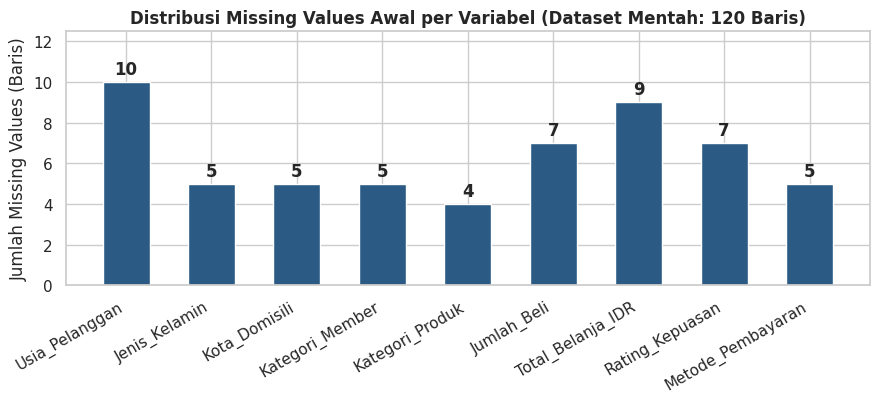

In [ ]:
audit_table = pd.DataFrame({
    'Nama Variabel': df_raw.columns,
    'Tipe Awal': df_raw.dtypes.astype(str).values,
    'Kategori Data': [
        'Kategorik (ID)', 'Temporal', 'Numerik', 'Kategorik Nominal',
        'Kategorik Nominal', 'Kategorik Ordinal', 'Kategorik Nominal',
        'Numerik', 'Numerik', 'Numerik', 'Kategorik Nominal'
    ],
    'Missing': df_raw.isnull().sum().values,
    '% Missing': (df_raw.isnull().sum().values / len(df_raw) * 100).round(2)
})
display(audit_table)

# Grafik Batang Distribusi Missing Values Awal
fig, ax = plt.subplots(figsize=(9, 4.2))
cols_with_miss = df_raw.columns[df_raw.isnull().sum() > 0]
miss_vals = df_raw[cols_with_miss].isnull().sum()

bars = ax.bar(cols_with_miss, miss_vals, color='#2B5B84', width=0.55)
ax.set_ylabel('Jumlah Missing Values (Baris)')
ax.set_title('Distribusi Missing Values Awal per Variabel (Dataset Mentah: 120 Baris)', fontweight='bold')
ax.set_ylim(0, max(miss_vals) + 2.5)
plt.xticks(rotation=30, ha='right')

for bar in bars:
    h = bar.get_height()
    ax.annotate(f'{int(h)}', xy=(bar.get_x() + bar.get_width() / 2, h),
                xytext=(0, 3), textcoords='offset points', ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()

In [ ]:
# Inspeksi nilai unik pada setiap kolom kategorik untuk mendeteksi typo, spasi, dan inkonsistensi huruf
cat_cols = ['Jenis_Kelamin', 'Kota_Domisili', 'Kategori_Member', 'Kategori_Produk', 'Metode_Pembayaran']
for col in cat_cols:
    print(f'--- Nilai unik {col} ---')
    print(df_raw[col].unique())
    print()

--- Nilai unik Jenis_Kelamin ---
['Perempuan' 'Laki-laki' nan 'laki-laki' 'Pria' 'L' 'P' 'Wanita'
 'perempuan' '  Perempuan ']

--- Nilai unik Kota_Domisili ---
['Bandung' 'Malang' nan 'Sidoarjo' 'MALANG' 'Surabaya' 'Jakarta' 'gresik'
 '  Surabaya  ' 'Gresik' 'SBY' 'surabaya' '  jakarta ']

--- Nilai unik Kategori_Member ---
['Gold' 'Bronze' 'Silver' nan 'GOLD' 'Platinum' 'platinum' '  Bronze '
 'Sliver' 'gold']

--- Nilai unik Kategori_Produk ---
['Makanan & Minuman' 'Rumah Tangga' 'Kesehatan & Kecantikan' 'Fashion'
 'elektronik' 'Elektronik' 'Makanan & minuman' nan 'Elektronic'
 '  Fashion ']

--- Nilai unik Metode_Pembayaran ---
['COD' 'Transfer Bank' 'E-Wallet' 'Kartu Kredit' nan 'TF Bank' '  COD '
 'Ewallet' 'e-wallet' 'cod']



## 3. Data Cleaning (Duplikat, Standardisasi Format, Typo, & Noise)
Pada tahap ini kita menyalin `df_raw` ke `df` lalu melakukan:
1. Penghapusan baris duplikat dan duplikat `ID_Transaksi`.
2. Pembersihan spasi, kapitalisasi, dan pemetaan *typo*/singkatan pada variabel kategorik.
3. Penyeragaman format `Tanggal_Transaksi` menjadi tipe `datetime`.
4. Pengubahan nilai tidak valid/*noise* (usia negatif/0/>100, jumlah beli <=0, total belanja <=0, rating di luar skala 1–5) menjadi `NaN` agar dapat diimputasi secara akurat.

In [ ]:
df = df_raw.copy()

# 3.1 Hapus duplikat identik dan duplikat ID_Transaksi
before_dup = len(df)
df = df.drop_duplicates().drop_duplicates(subset=['ID_Transaksi'], keep='first').reset_index(drop=True)
print(f'Baris sebelum hapus duplikat: {before_dup} -> Sesudah: {len(df)} (Dihapus: {before_dup - len(df)} baris)')

Baris sebelum hapus duplikat: 120 -> Sesudah: 113 (Dihapus: 7 baris)


In [ ]:
# 3.2 Standardisasi teks dan perbaikan typo pada variabel kategorik
for col in cat_cols:
    df[col] = df[col].astype('string').str.strip()

map_jk = {
    'laki-laki': 'Laki-laki', 'Laki-laki': 'Laki-laki', 'L': 'Laki-laki', 'Pria': 'Laki-laki',
    'perempuan': 'Perempuan', 'Perempuan': 'Perempuan', 'P': 'Perempuan', 'Wanita': 'Perempuan'
}
df['Jenis_Kelamin'] = df['Jenis_Kelamin'].replace(map_jk)

map_kota = {
    'surabaya': 'Surabaya', 'Surabaya': 'Surabaya', 'SBY': 'Surabaya',
    'gresik': 'Gresik', 'Gresik': 'Gresik',
    'sidoarjo': 'Sidoarjo', 'Sidoarjo': 'Sidoarjo',
    'malang': 'Malang', 'MALANG': 'Malang', 'Malang': 'Malang',
    'jakarta': 'Jakarta', 'Jakarta': 'Jakarta',
    'bandung': 'Bandung', 'Bandung': 'Bandung'
}
df['Kota_Domisili'] = df['Kota_Domisili'].replace(map_kota)

map_member = {
    'bronze': 'Bronze', 'Bronze': 'Bronze',
    'silver': 'Silver', 'Silver': 'Silver', 'Sliver': 'Silver',
    'gold': 'Gold', 'GOLD': 'Gold', 'Gold': 'Gold',
    'platinum': 'Platinum', 'Platinum': 'Platinum'
}
df['Kategori_Member'] = df['Kategori_Member'].replace(map_member)

map_produk = {
    'elektronik': 'Elektronik', 'Elektronic': 'Elektronik', 'Elektronik': 'Elektronik',
    'fashion': 'Fashion', 'Fashion': 'Fashion',
    'Kesehatan & Kecantikan': 'Kesehatan & Kecantikan',
    'Rumah Tangga': 'Rumah Tangga',
    'Makanan & minuman': 'Makanan & Minuman', 'Makanan & Minuman': 'Makanan & Minuman'
}
df['Kategori_Produk'] = df['Kategori_Produk'].replace(map_produk)

map_metode = {
    'e-wallet': 'E-Wallet', 'Ewallet': 'E-Wallet', 'E-Wallet': 'E-Wallet',
    'TF Bank': 'Transfer Bank', 'Transfer Bank': 'Transfer Bank',
    'cod': 'COD', 'COD': 'COD',
    'Kartu Kredit': 'Kartu Kredit'
}
df['Metode_Pembayaran'] = df['Metode_Pembayaran'].replace(map_metode)

# Konversi kembali ke tipe object standar pandas
for col in cat_cols:
    df[col] = df[col].astype(object).where(df[col].notna(), np.nan)

# 3.3 Standardisasi format Tanggal_Transaksi
df['Tanggal_Transaksi'] = pd.to_datetime(df['Tanggal_Transaksi'], format='mixed')
print('Tipe data Tanggal_Transaksi setelah standardisasi:', df['Tanggal_Transaksi'].dtype)

Tipe data Tanggal_Transaksi setelah standardisasi: datetime64[ns]


In [ ]:
# 3.4 Ubah nilai tidak valid / noise menjadi NaN
df.loc[(df['Usia_Pelanggan'] < 17) | (df['Usia_Pelanggan'] > 100), 'Usia_Pelanggan'] = np.nan
df.loc[df['Jumlah_Beli'] <= 0, 'Jumlah_Beli'] = np.nan
df.loc[df['Total_Belanja_IDR'] <= 0, 'Total_Belanja_IDR'] = np.nan
df.loc[(df['Rating_Kepuasan'] < 1.0) | (df['Rating_Kepuasan'] > 5.0), 'Rating_Kepuasan'] = np.nan

print('\nVerifikasi nilai unik kategorik setelah standardisasi:')
for col in cat_cols:
    print(f'{col}: {df[col].dropna().unique().tolist()}')


Verifikasi nilai unik kategorik setelah standardisasi:
Jenis_Kelamin: ['Perempuan', 'Laki-laki']
Kota_Domisili: ['Bandung', 'Malang', 'Surabaya', 'Sidoarjo', 'Jakarta', 'Gresik']
Kategori_Member: ['Gold', 'Bronze', 'Silver', 'Platinum']
Kategori_Produk: ['Makanan & Minuman', 'Rumah Tangga', 'Kesehatan & Kecantikan', 'Fashion', 'Elektronik']
Metode_Pembayaran: ['COD', 'Transfer Bank', 'E-Wallet', 'Kartu Kredit']


## 4. Penanganan Missing Values Berbasis Statistik Deskriptif
Sesuai ketentuan tugas, sebelum mengisi nilai kosong (*missing values*), kita menghitung **statistik deskriptif lengkap** (Count, Mean, Median, Modus, Std, Min, Q1, Q3, Max, dan Skewness) untuk menentukan metode imputasi terbaik:
- **Variabel Numerik dengan Skewness tinggi / memiliki outlier (`Usia_Pelanggan`, `Jumlah_Beli`, `Total_Belanja_IDR`)**: menggunakan **Median** karena lebih tahan (*robust*) terhadap nilai ekstrem.
- **Variabel Numerik dengan distribusi simetris (`Rating_Kepuasan`)**: menggunakan **Mean**.
- **Variabel Kategorik**: menggunakan **Modus** (nilai dengan frekuensi kemunculan tertinggi).

In [ ]:
num_cols = ['Usia_Pelanggan', 'Jumlah_Beli', 'Total_Belanja_IDR', 'Rating_Kepuasan']

# Tabel Statistik Deskriptif sebelum imputasi
desc_num = df[num_cols].describe().T
desc_num['median'] = df[num_cols].median()
desc_num['mode'] = [df[c].mode()[0] for c in num_cols]
desc_num['skewness'] = df[num_cols].skew()
desc_num['missing'] = df[num_cols].isnull().sum()
print('=== STATISTIK DESKRIPTIF NUMERIK (SEBELUM IMPUTASI) ===')
display(desc_num[['count', 'missing', 'mean', 'median', 'mode', 'std', 'min', '50%', 'max', 'skewness']])

# Imputasi Variabel Numerik
df['Usia_Pelanggan'] = df['Usia_Pelanggan'].fillna(round(df['Usia_Pelanggan'].median()))
df['Jumlah_Beli'] = df['Jumlah_Beli'].fillna(round(df['Jumlah_Beli'].median()))
df['Total_Belanja_IDR'] = df['Total_Belanja_IDR'].fillna(df['Total_Belanja_IDR'].median())
df['Rating_Kepuasan'] = df['Rating_Kepuasan'].fillna(round(df['Rating_Kepuasan'].mean(), 1))

# Tabel Frekuensi & Modus Variabel Kategorik sebelum imputasi
print('\n=== DISTRIBUSI & MODUS VARIABEL KATEGORIK (SEBELUM IMPUTASI) ===')
for col in cat_cols:
    modus_val = df[col].mode()[0]
    miss_cnt = df[col].isnull().sum()
    print(f'{col:20s} | Missing: {miss_cnt} | Modus: {modus_val}')
    df[col] = df[col].fillna(modus_val)

print('\nTotal missing values setelah imputasi:', df.isnull().sum().sum())

=== STATISTIK DESKRIPTIF NUMERIK (SEBELUM IMPUTASI) ===


,count,missing,mean,median,mode,std,min,50%,max,skewness
Usia_Pelanggan,101.0,12,3.021782e+01,30.0,29.0,6.017647e+00,18.0,30.0,44.0,0.025030
Jumlah_Beli,105.0,8,1.491429e+01,4.0,4.0,8.200025e+01,1.0,4.0,720.0,7.693164
Total_Belanja_IDR,103.0,10,3.668767e+06,710000.0,528000.0,1.601314e+07,128000.0,710000.0,125000000.0,6.312772
Rating_Kepuasan,103.0,10,4.252427e+00,4.3,3.9,4.789377e-01,3.0,4.3,5.0,-0.347171



=== DISTRIBUSI & MODUS VARIABEL KATEGORIK (SEBELUM IMPUTASI) ===
Jenis_Kelamin        | Missing: 5 | Modus: Perempuan
Kota_Domisili        | Missing: 5 | Modus: Surabaya
Kategori_Member      | Missing: 5 | Modus: Bronze
Kategori_Produk      | Missing: 4 | Modus: Fashion
Metode_Pembayaran    | Missing: 5 | Modus: E-Wallet

Total missing values setelah imputasi: 0


## 5. Deteksi dan Penanganan Outliers (Metode IQR / Capping)
Nilai ekstrem pada `Jumlah_Beli` (450 & 720 unit) dan `Total_Belanja_IDR` (hingga Rp 125.000.000) dideteksi menggunakan aturan **Interquartile Range (IQR)**:
- $\text{Batas Bawah} = Q_1 - 1.5 \times \text{IQR}$
- $\text{Batas Atas} = Q_3 + 1.5 \times \text{IQR}$

Agar tidak kehilangan jumlah baris sampel pada dataset berukuran 113 baris, nilai di atas batas atas ditangani menggunakan metode **Capping (Winsorization)**.

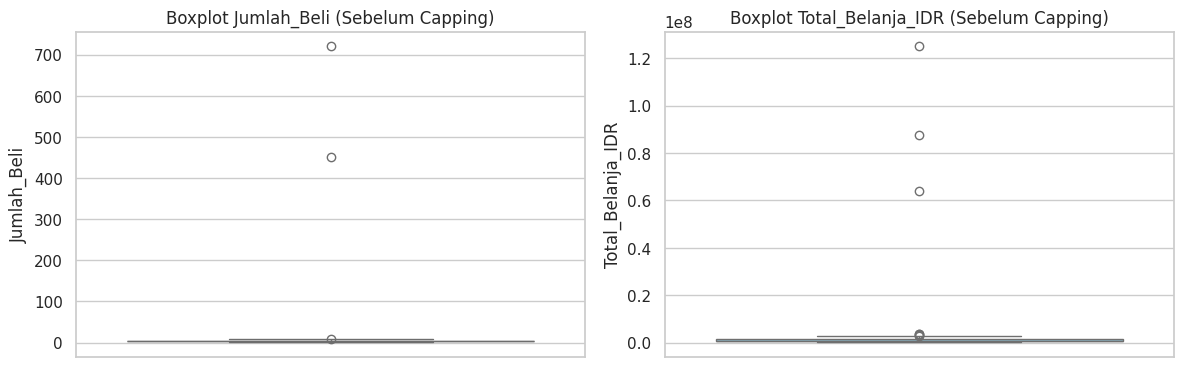


=== PERHITUNGAN BATAS IQR & PENANGANAN OUTLIERS ===
Jumlah_Beli        | Q1=3, Q3=5, Batas Atas=8 | Outlier=3
Total_Belanja_IDR  | Q1=478,000, Q3=1,438,000, Batas Atas=2,878,000 | Outlier=7


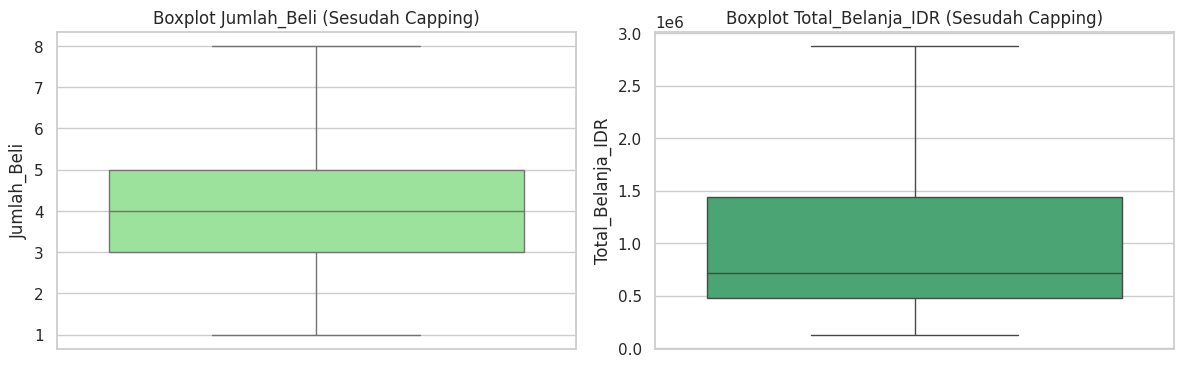


=== STATISTIK DESKRIPTIF SETELAH CLEANING & OUTLIER HANDLING ===


,count,mean,std,min,25%,50%,75%,max
Usia_Pelanggan,113.0,3.019469e+01,5.686542,18.0,27.0,30.0,33.0,44.0
Jumlah_Beli,113.0,3.920354e+00,1.518585,1.0,3.0,4.0,5.0,8.0
Total_Belanja_IDR,113.0,1.021885e+06,764973.024177,128000.0,478000.0,710000.0,1438000.0,2878000.0
Rating_Kepuasan,113.0,4.256637e+00,0.457258,3.0,3.9,4.3,4.5,5.0


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(y=df['Jumlah_Beli'], ax=axes[0], color='salmon')
axes[0].set_title('Boxplot Jumlah_Beli (Sebelum Capping)')
sns.boxplot(y=df['Total_Belanja_IDR'], ax=axes[1], color='skyblue')
axes[1].set_title('Boxplot Total_Belanja_IDR (Sebelum Capping)')
plt.tight_layout()
plt.show()

print("\n=== PERHITUNGAN BATAS IQR & PENANGANAN OUTLIERS ===")
for col in ['Jumlah_Beli', 'Total_Belanja_IDR']:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = max(1, Q1 - 1.5 * IQR)
    upper_bound = Q3 + 1.5 * IQR
    n_outliers = ((df[col] < lower_bound) | (df[col] > upper_bound)).sum()
    print(f"{col:18s} | Q1={Q1:,.0f}, Q3={Q3:,.0f}, Batas Atas={upper_bound:,.0f} | Outlier={n_outliers}")
    df[col] = np.clip(df[col], lower_bound, upper_bound)

df['Usia_Pelanggan'] = df['Usia_Pelanggan'].astype(int)
df['Jumlah_Beli'] = df['Jumlah_Beli'].round().astype(int)

# Visualisasi Boxplot SESUDAH Capping (untuk perbandingan Output di laporan)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(y=df['Jumlah_Beli'], ax=axes[0], color='lightgreen')
axes[0].set_title('Boxplot Jumlah_Beli (Sesudah Capping)')
sns.boxplot(y=df['Total_Belanja_IDR'], ax=axes[1], color='mediumseagreen')
axes[1].set_title('Boxplot Total_Belanja_IDR (Sesudah Capping)')
plt.tight_layout()
plt.show()

print("\n=== STATISTIK DESKRIPTIF SETELAH CLEANING & OUTLIER HANDLING ===")
display(df[num_cols].describe().T)

## 6. Reduksi Data, Encoding, dan Feature Scaling (Transformasi)
Tahap akhir persiapan data sebelum pemodelan Machine Learning:
1. **Reduksi & Ekstraksi Fitur**: Menghapus kolom pengenal unik `ID_Transaksi` dan mengekstrak `Bulan_Transaksi` dari `Tanggal_Transaksi`.
2. **Ordinal Encoding**: Mengubah tingkatan `Kategori_Member` (`Bronze`=1, `Silver`=2, `Gold`=3, `Platinum`=4) sesuai urutan hierarkinya.
3. **One-Hot Encoding**: Mengubah variabel kategorik nominal (`Jenis_Kelamin`, `Kota_Domisili`, `Kategori_Produk`, `Metode_Pembayaran`) menjadi kolom biner.
4. **Feature Scaling**: Menyamakan skala variabel numerik menggunakan `StandardScaler` (Z-score).

In [ ]:
# Simpan versi bersih yang masih mudah dibaca manusia (human-readable)
df_clean_readable = df.copy()
df_clean_readable.to_csv('dataset_transaksi_ecommerce_bersih.csv', index=False)

# Siapkan versi siap pemodelan (Model-Ready)
df_model = df.copy()
df_model['Bulan_Transaksi'] = df_model['Tanggal_Transaksi'].dt.month
df_model = df_model.drop(columns=['ID_Transaksi', 'Tanggal_Transaksi'])

# Ordinal Encoding untuk Kategori_Member
member_order = {'Bronze': 1, 'Silver': 2, 'Gold': 3, 'Platinum': 4}
df_model['Kategori_Member_Encoded'] = df_model['Kategori_Member'].map(member_order)
df_model = df_model.drop(columns=['Kategori_Member'])

# One-Hot Encoding untuk fitur kategorik nominal
nominal_cols = ['Jenis_Kelamin', 'Kota_Domisili', 'Kategori_Produk', 'Metode_Pembayaran']
df_model = pd.get_dummies(df_model, columns=nominal_cols, drop_first=True, dtype=int)

# Feature Scaling (StandardScaler) pada fitur numerik
scaler = StandardScaler()
scale_cols = ['Usia_Pelanggan', 'Jumlah_Beli', 'Total_Belanja_IDR', 'Rating_Kepuasan']
df_model[scale_cols] = scaler.fit_transform(df_model[scale_cols])

df_model.to_csv('dataset_transaksi_ecommerce_model_ready.csv', index=False)
print(f'Ukuran dataset siap pemodelan: {df_model.shape[0]} baris x {df_model.shape[1]} kolom')
df_model.head()

Ukuran dataset siap pemodelan: 113 baris x 19 kolom


,Usia_Pelanggan,Jumlah_Beli,Total_Belanja_IDR,Rating_Kepuasan,Bulan_Transaksi,Kategori_Member_Encoded,Jenis_Kelamin_Perempuan,Kota_Domisili_Gresik,Kota_Domisili_Jakarta,Kota_Domisili_Malang,Kota_Domisili_Sidoarjo,Kota_Domisili_Surabaya,Kategori_Produk_Fashion,Kategori_Produk_Kesehatan & Kecantikan,Kategori_Produk_Makanan & Minuman,Kategori_Produk_Rumah Tangga,Metode_Pembayaran_E-Wallet,Metode_Pembayaran_Kartu Kredit,Metode_Pembayaran_Transfer Bank
0,-0.034390,0.052681,-0.673448,0.095255,5,3,1,0,0,0,0,0,0,0,1,0,0,0,0
1,1.378707,0.052681,-0.873033,1.413269,5,3,0,0,0,1,0,0,0,0,0,1,0,0,1
2,-0.211027,-0.608760,-0.945251,0.095255,1,3,1,0,0,1,0,0,0,1,0,0,1,0,0
3,1.378707,1.375563,0.274580,-0.783421,5,1,1,0,0,0,0,1,1,0,0,0,1,0,0
4,-1.270849,-0.608760,-0.951816,1.632938,3,1,1,0,0,0,1,0,0,0,0,0,1,0,0
